# Experiment 2: text-to-image retrieval with BiomedCLIP on ROCOv2 (validation split)

1. Build the image database: all validation images -> normalised BiomedCLIP image embeddings (+ IDs, captions)
2. Prepare text queries: hand-written descriptions **and** original ROCOv2 captions
3. Encode the queries with the BiomedCLIP text encoder
4. Cosine similarity: every query against every image
5. Rank and display the top-k images per query
6. Evaluate: caption -> its own image, Recall@1 / @5 / @10
7. Analyse the results

Both encoders map into the same 512-d space and are L2-normalised, so a dot product **is** the cosine similarity.

## 0. Configuration 

In [1]:
from pathlib import Path

DATA_DIR = Path("data/ROCOv2")          # folder with valid_images.zip, valid_captions.csv, valid_concepts_manual.csv
SPLIT = "valid"

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
EMB_CACHE = OUT_DIR / "valid_image_embeddings.npz"       # written/re-used by this notebook
EXP1_CACHE = OUT_DIR / "exp1_image_embeddings.npz"       # optional: saved from the classification notebook

N_GALLERY = 1000            # images in the search database. None = ALL validation images (~9.9k; slow on CPU).
                            # A smaller gallery is an easier task, so Recall is higher than with the full set.
N_EVAL_QUERIES = 500        # captions used as queries in step 7 (None = all captions of the gallery)
TOP_K_SHOW = 5              # images shown per query
KS = (1, 5, 10)             # Recall@K
SEED = 42
BATCH_SIZE = 64

MODEL_ID = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
CONTEXT_LENGTH = 256

## 1. Imports, device, model

In [2]:
import io
import textwrap
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from open_clip import create_model_from_pretrained, get_tokenizer
from PIL import Image
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
                      else "cpu")
print("Device:", device)

model, preprocess = create_model_from_pretrained(MODEL_ID)
tokenizer = get_tokenizer(MODEL_ID)
model = model.to(device).eval()
print("Model loaded.")

c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\transformers\utils\generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\transformers\utils\generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Device: cpu


c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Model loaded.


## 2. Image database: IDs, captions, modality

The gallery is **every** validation image that has a caption and is present in the zip.
Modality (from the manual CUIs) is kept only for analysis later; images without a manual modality get `n/a`.

In [3]:
CUI_TO_MODALITY = {"C0040405": "CT", "C0024485": "MRI", "C0041618": "ultrasound",
                   "C0002978": "angiography", "C0032743": "PET", "C1306645": "X-ray"}


def read_two_cols(path, names):
    df = pd.read_csv(path, header=0, usecols=[0, 1], dtype=str, keep_default_na=False)
    df.columns = names
    df["image_id"] = df["image_id"].str.replace(r"\.(jpe?g|png)$", "", regex=True, case=False)
    return df


def modality_of(cuis):
    found = {CUI_TO_MODALITY[c] for c in cuis.split(";") if c in CUI_TO_MODALITY}
    return next(iter(found)) if len(found) == 1 else None


captions = read_two_cols(DATA_DIR / f"{SPLIT}_captions.csv", ["image_id", "caption"])
manual = read_two_cols(DATA_DIR / f"{SPLIT}_concepts_manual.csv", ["image_id", "cuis"])
manual["modality"] = manual["cuis"].map(modality_of)

zf = zipfile.ZipFile(DATA_DIR / f"{SPLIT}_images.zip")
zip_index = {Path(n).stem: n for n in zf.namelist() if n.lower().endswith((".jpg", ".jpeg", ".png"))}


def load_pil(image_id):
    return Image.open(io.BytesIO(zf.read(zip_index[image_id]))).convert("RGB")


db = captions.merge(manual[["image_id", "modality"]], on="image_id", how="left")
db["modality"] = db["modality"].fillna("n/a")
db = db[(db["caption"].str.strip() != "") & db["image_id"].isin(zip_index)]
db = db.drop_duplicates("image_id").reset_index(drop=True)
if db.empty:
    raise RuntimeError(f"No caption IDs matched the zip. Zip members look like {list(zip_index)[:3]}")

cap_lookup = dict(zip(captions["image_id"], captions["caption"]))       # for storing captions next to the embeddings
n_available = len(db)
if N_GALLERY is not None and N_GALLERY < n_available:                   # quick mode: random subset as the gallery
    db = db.sample(n=N_GALLERY, random_state=SEED).sort_index().reset_index(drop=True)
    print(f"QUICK MODE: gallery = {len(db)} of {n_available} images (set N_GALLERY = None for all)\n")

db["n_words"] = db["caption"].str.split().str.len()
db["cap_key"] = db["caption"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()   # for duplicate detection

dup_share = (db["cap_key"].map(db["cap_key"].value_counts()) > 1).mean()
print(f"Image database: {len(db)} images")
print(db["modality"].value_counts().to_string())
print(f"\nCaptions: mean {db['n_words'].mean():.1f} words, max {db['n_words'].max()}; "
      f"{dup_share:.1%} of images share an identical caption with another image")
db.head()

QUICK MODE: gallery = 1000 of 9903 images (set N_GALLERY = None for all)

Image database: 1000 images
modality
CT             381
X-ray          239
ultrasound     174
MRI            153
angiography     37
n/a             11
PET              5

Captions: mean 22.1 words, max 199; 0.0% of images share an identical caption with another image


,image_id,caption,modality,n_words,cap_key
0,ROCOv2_2023_valid_000001,Chest X-ray showing enlarged cardiac silhouett...,X-ray,15,chest x-ray showing enlarged cardiac silhouett...
1,ROCOv2_2023_valid_000004,CT scan image for lung cancer.,CT,6,ct scan image for lung cancer.
2,ROCOv2_2023_valid_000009,Late sagittal T2-weighted MRI.,MRI,4,late sagittal t2-weighted mri.
3,ROCOv2_2023_valid_000015,Retrograde portography performed with 40 mL io...,angiography,15,retrograde portography performed with 40 ml io...
4,ROCOv2_2023_valid_000024,The typical computer tomography of the chest ...,CT,20,the typical computer tomography of the chest f...


### Image embeddings (re-used when possible)


In [4]:
import time

test_ids = db["image_id"].iloc[:16].tolist()
t0 = time.perf_counter()
tensors = [preprocess(load_pil(i)) for i in test_ids]
t_load = time.perf_counter() - t0
x = torch.stack(tensors).to(device)
t0 = time.perf_counter()
with torch.inference_mode():
    model.encode_image(x, normalize=True)
if device.type == "cuda":
    torch.cuda.synchronize()
t_model = time.perf_counter() - t0

n = len(test_ids)
print(f"device: {device} | torch threads: {torch.get_num_threads()}")
print(f"read+decode+preprocess: {t_load / n * 1000:6.0f} ms/image")
print(f"model forward pass    : {t_model / n * 1000:6.0f} ms/image")
print(f"-> estimated time for {len(db)} images: {len(db) * (t_load + t_model) / n / 60:.1f} min")

device: cpu | torch threads: 2
read+decode+preprocess:     90 ms/image
model forward pass    :   1123 ms/image
-> estimated time for 1000 images: 20.2 min


In [ ]:
known = {}                                              # image_id -> embedding already computed
for cache in (EMB_CACHE, EXP1_CACHE):
    if cache.exists():
        z = np.load(cache, allow_pickle=False)
        known.update(zip(z["ids"].tolist(), z["emb"]))
        print(f"loaded {len(z['ids'])} embeddings from {cache}")


def save_cache():
    ids = list(known)
    np.savez(EMB_CACHE, ids=np.array(ids, dtype=str), emb=np.stack([known[i] for i in ids]),
             captions=np.array([cap_lookup.get(i, "") for i in ids], dtype=str))


def encode_images(ids, batch_size=BATCH_SIZE, save_every=10):
    try:
        for b, i in enumerate(tqdm(range(0, len(ids), batch_size), desc="encoding images")):
            chunk = ids[i:i + batch_size]
            x = torch.stack([preprocess(load_pil(c)) for c in chunk]).to(device)
            with torch.inference_mode():
                emb = model.encode_image(x, normalize=True).float().cpu().numpy()
            known.update(zip(chunk, emb))
            if (b + 1) % save_every == 0:
                save_cache()
    finally:
        save_cache()          


todo = [i for i in db["image_id"] if i not in known]
print(f"re-used {len(db) - len(todo)} embeddings, encoding {len(todo)} new images")
if todo:
    encode_images(todo)

image_emb = np.stack([known[i] for i in db["image_id"]]).astype(np.float32)      # (N, 512), row i <-> db.iloc[i]
db.drop(columns=["cap_key"]).to_csv(OUT_DIR / "valid_image_database.csv", index=False)

norms = np.linalg.norm(image_emb, axis=1)
print("image_emb:", image_emb.shape, f"| norms min/max {norms.min():.4f}/{norms.max():.4f} (should be 1)")
assert np.allclose(norms, 1, atol=1e-3), "embeddings are not normalised"

loaded 1218 embeddings from outputs\valid_image_embeddings.npz
loaded 238 embeddings from outputs\exp1_image_embeddings.npz
re-used 1000 embeddings, encoding 0 new images
image_emb: (1000, 512) | norms min/max 1.0000/1.0000 (should be 1)


## 3. Text queries

* **Manual queries:** hand-written descriptions. Where the intended modality is clear it is listed too, so we can
  check how many of the top-10 results have that modality (a quick sanity check that needs no caption ground truth).
* **Caption queries:** original ROCOv2 captions; the ground-truth answer is the image the caption belongs to.

In [6]:
MANUAL_QUERIES = {                                   # query -> expected modality (None = no manual label exists)
    "Chest X-ray showing pneumonia": "X-ray",
    "Brain MRI showing a tumor": "MRI",
    "CT scan of the abdomen": "CT",
    "Ultrasound of the heart showing pericardial effusion": "ultrasound",
    "Coronary angiography showing stenosis": "angiography",
    "PET/CT showing lymph node metastases": None,
    "Mammogram of the breast": "X-ray",
    "MRI of the knee showing a ligament tear": "MRI",
    "Chest CT showing pulmonary embolism": "CT",
    "Obstetric ultrasound of a fetus": "ultrasound",
    "Panoramic dental radiograph": "X-ray",
    "Brain CT showing intracranial hemorrhage": "CT",
}
manual_texts = list(MANUAL_QUERIES)

rng = np.random.default_rng(SEED)
N = len(db)
if N_EVAL_QUERIES is None or N_EVAL_QUERIES >= N:
    eval_idx = np.arange(N)
else:
    eval_idx = np.sort(rng.choice(N, size=N_EVAL_QUERIES, replace=False))
query_captions = db["caption"].iloc[eval_idx].tolist()      # query j  <->  true image = db row eval_idx[j]

print(f"{len(manual_texts)} manual queries | {len(eval_idx)} caption queries against a gallery of {N} images")

12 manual queries | 500 caption queries against a gallery of 1000 images


## 4. Encode the queries (tokenise -> text encoder -> normalised embedding)

In [7]:
@torch.inference_mode()
def encode_texts(texts, batch_size=128):
    out = []
    for i in tqdm(range(0, len(texts), batch_size), desc="encoding text", disable=len(texts) <= batch_size):
        tok = tokenizer(texts[i:i + batch_size], context_length=CONTEXT_LENGTH).to(device)   # longer captions are truncated
        out.append(model.encode_text(tok, normalize=True).float().cpu().numpy())
    return np.concatenate(out).astype(np.float32)


manual_emb = encode_texts(manual_texts)
cap_emb = encode_texts(query_captions)
print("manual_emb:", manual_emb.shape, "| cap_emb:", cap_emb.shape)

encoding text:   0%|          | 0/4 [00:00<?, ?it/s]

manual_emb: (12, 512) | cap_emb: (500, 512)


## 5. Image-text similarity matrix

`sim = text_emb @ image_emb.T` gives one cosine similarity per (query, image) pair.
For the manual queries that is a `(12 x N)` matrix. The heat-map below shows how each query scores against the
*top-1 image of every query*: a clear diagonal means the queries retrieve distinct, matching images.

similarity matrix: (12, 1000) | min -0.180  mean 0.188  max 0.470


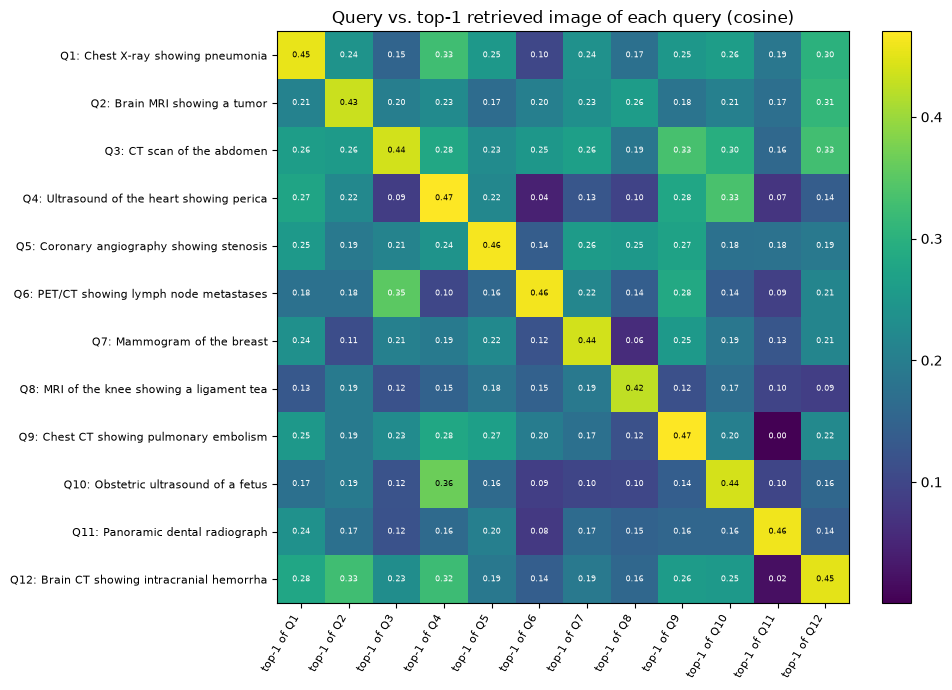

In [8]:
sim_manual = manual_emb @ image_emb.T
print("similarity matrix:", sim_manual.shape, f"| min {sim_manual.min():.3f}  mean {sim_manual.mean():.3f}  max {sim_manual.max():.3f}")

top1 = sim_manual.argmax(axis=1)
cross = manual_emb @ image_emb[top1].T                     # (Q, Q)
Q = len(manual_texts)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cross, cmap="viridis")
ax.set_xticks(range(Q), labels=[f"top-1 of Q{i + 1}" for i in range(Q)], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(Q), labels=[f"Q{i + 1}: {t[:38]}" for i, t in enumerate(manual_texts)], fontsize=8)
for r in range(Q):
    for c in range(Q):
        ax.text(c, r, f"{cross[r, c]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if cross[r, c] < cross.max() * 0.75 else "black")
ax.set_title("Query vs. top-1 retrieved image of each query (cosine)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 6. Retrieve and rank: top-k images with captions and scores

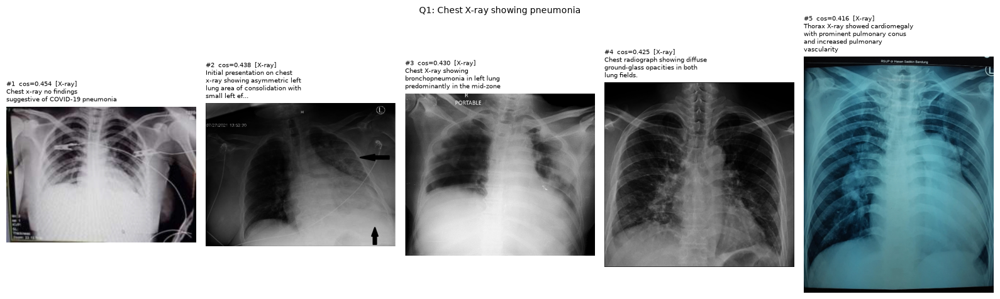

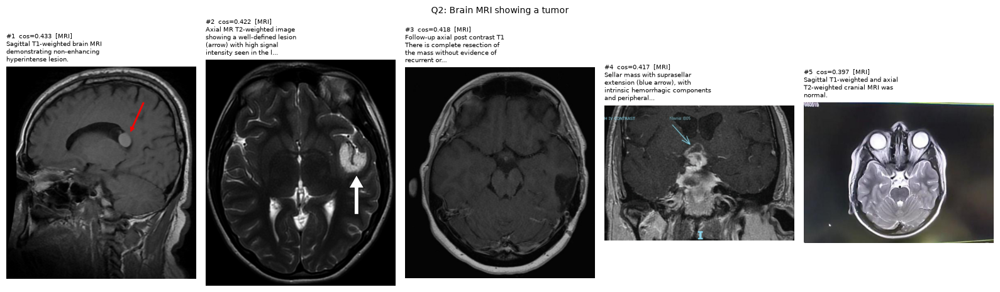

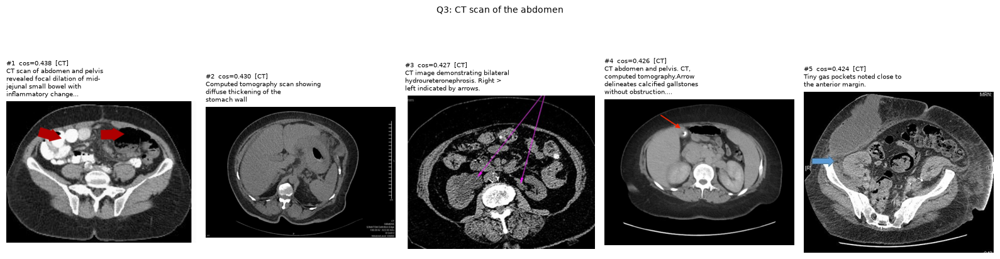

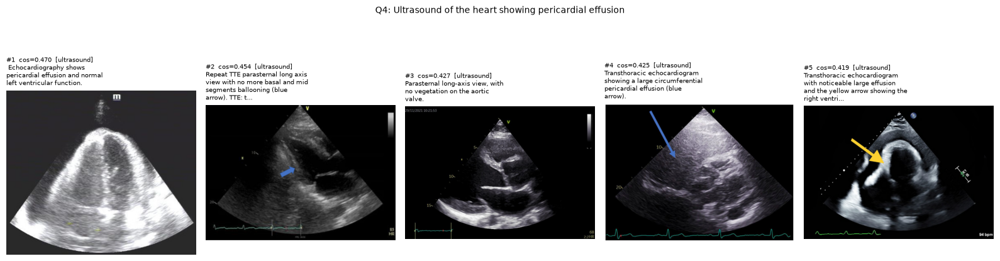

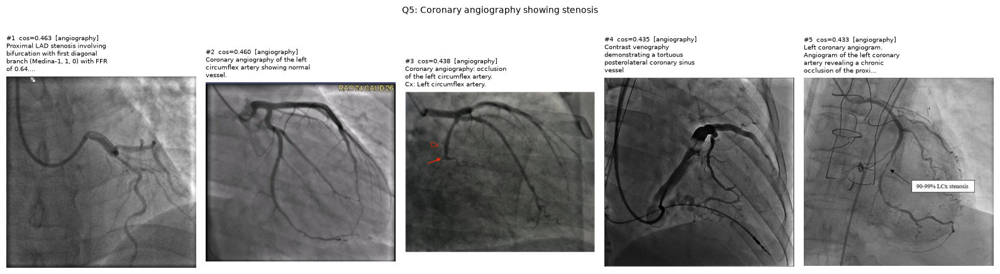

...

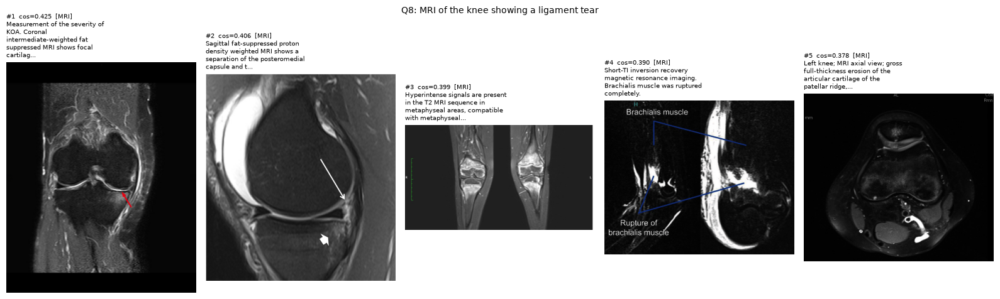

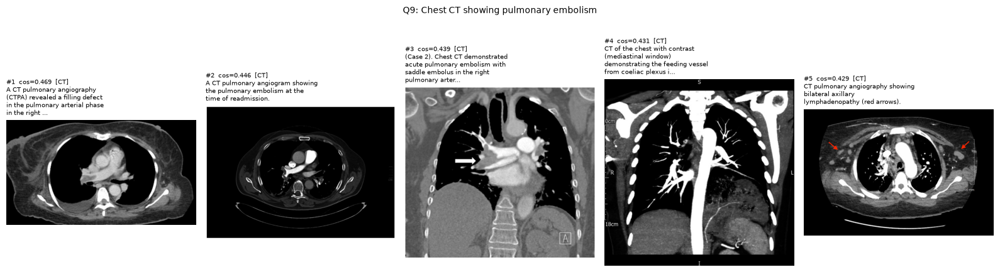

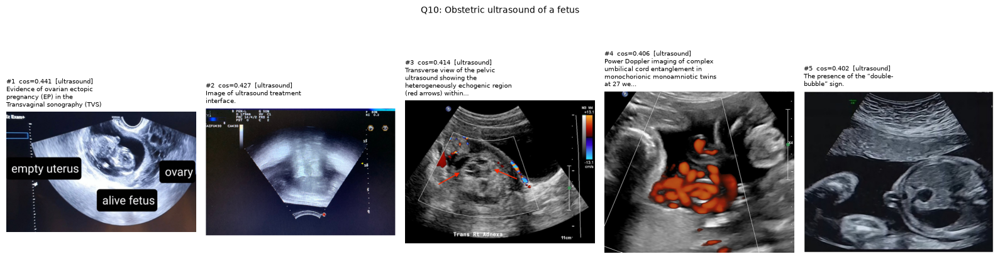

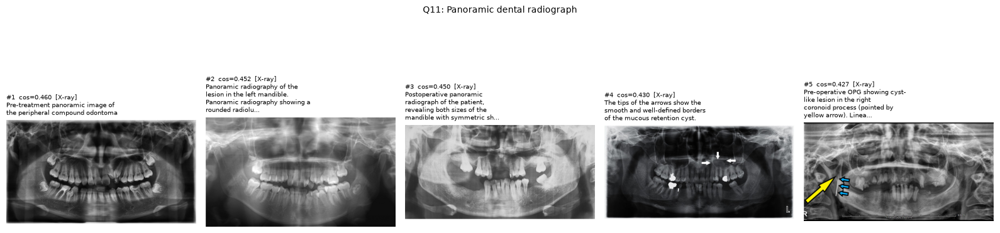

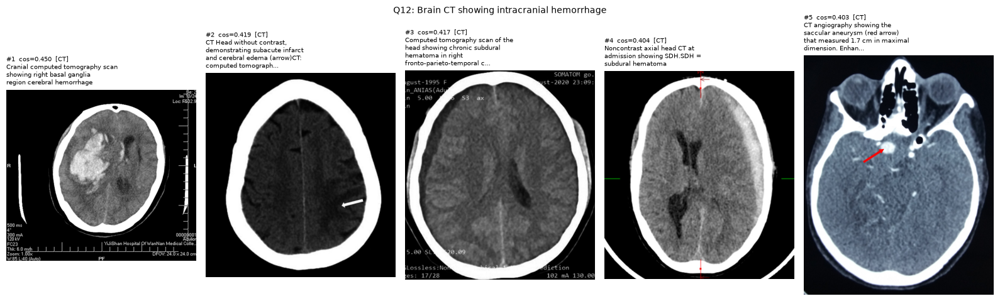

,query,expected modality,top-1 modality,top-10 with expected modality,top-1 score
0,Chest X-ray showing pneumonia,X-ray,X-ray,1.0,0.454
1,Brain MRI showing a tumor,MRI,MRI,1.0,0.433
2,CT scan of the abdomen,CT,CT,1.0,0.438
3,Ultrasound of the heart showing pericardial ef...,ultrasound,ultrasound,1.0,0.470
4,Coronary angiography showing stenosis,angiography,angiography,1.0,0.463
5,PET/CT showing lymph node metastases,-,n/a,NaN,0.463
6,Mammogram of the breast,X-ray,X-ray,0.3,0.438
7,MRI of the knee showing a ligament tear,MRI,MRI,1.0,0.425
8,Chest CT showing pulmonary embolism,CT,CT,1.0,0.469
9,Obstetric ultrasound of a fetus,ultrasound,ultrasound,1.0,0.441


In [9]:
def top_k_idx(scores, k):
    idx = np.argpartition(-scores, k - 1)[:k]
    return idx[np.argsort(-scores[idx])]


def show_retrieval(title, scores, k=TOP_K_SHOW, true_idx=None):
    idx = top_k_idx(scores, k)
    fig, axes = plt.subplots(1, k, figsize=(3.2 * k, 5.0))
    for rank, (ax, j) in enumerate(zip(np.atleast_1d(axes), idx), 1):
        ax.imshow(load_pil(db["image_id"][j]), cmap="gray")
        ax.axis("off")
        cap = db["caption"][j]
        cap = textwrap.fill(cap[:105] + ("..." if len(cap) > 105 else ""), 32)
        mark = "  <- TRUE" if true_idx is not None and j == true_idx else ""
        ax.set_title(f"#{rank}  cos={scores[j]:.3f}  [{db['modality'][j]}]{mark}\n{cap}",
                     fontsize=7, loc="left", color="green" if mark else "black")
    fig.suptitle(title, fontsize=10, y=1.0)
    plt.tight_layout()
    plt.show()
    return idx


rows = []
for q, (text, expected) in enumerate(MANUAL_QUERIES.items()):
    idx = show_retrieval(f"Q{q + 1}: {text}", sim_manual[q])
    top10 = top_k_idx(sim_manual[q], 10)
    rows.append({"query": text, "expected modality": expected or "-",
                 "top-1 modality": db["modality"][top10[0]],
                 "top-10 with expected modality": (np.mean(db["modality"].to_numpy()[top10] == expected)
                                                   if expected else np.nan),
                 "top-1 score": sim_manual[q, top10[0]]})
manual_summary = pd.DataFrame(rows)
manual_summary.round(3)

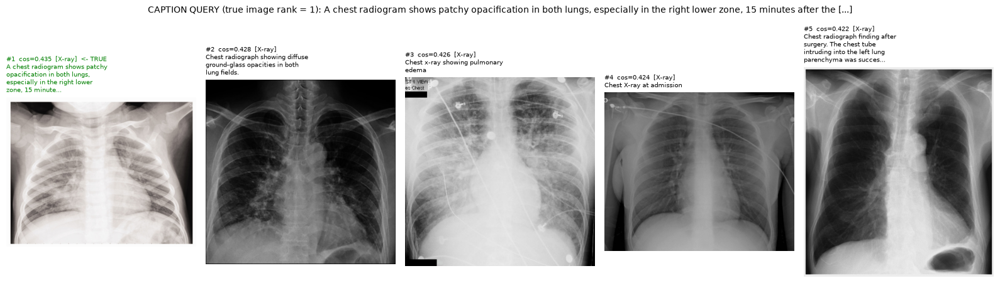

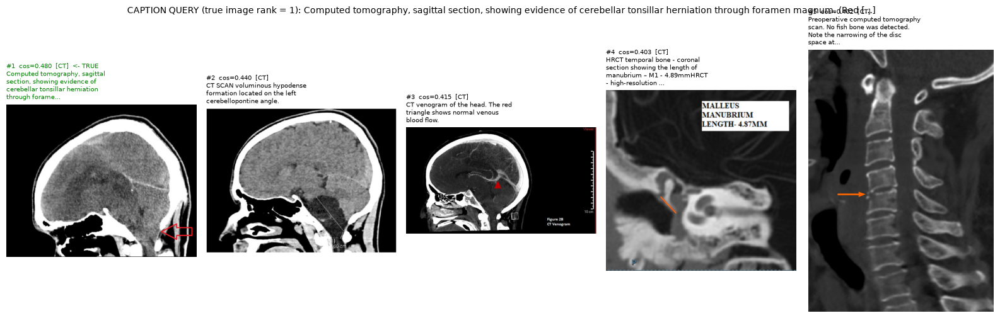

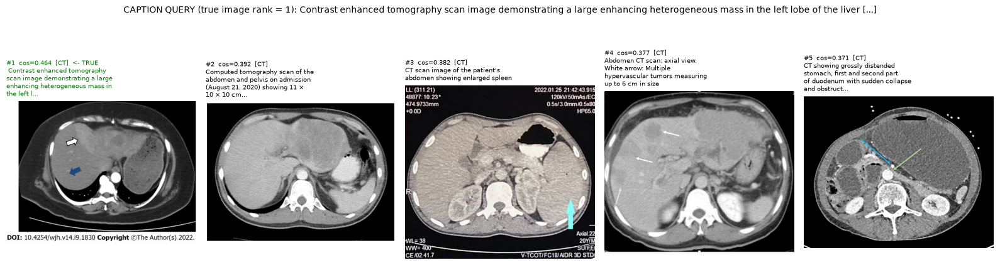

In [10]:
# Same display for a few ROCOv2 captions used as queries: the green title marks the caption's own image
for j in rng.choice(len(eval_idx), size=3, replace=False):
    s = cap_emb[j] @ image_emb.T
    true = eval_idx[j]
    rank = int((s > s[true]).sum() + 1)
    q = query_captions[j]
    show_retrieval(f"CAPTION QUERY (true image rank = {rank}): " + textwrap.shorten(q, 130), s, true_idx=true)

## 7. Evaluation: caption -> its own image

For each caption, rank all N images and record the position of the caption's own image.
Reported: **Recall@K** (own image in the top K), MRR, median rank, plus two diagnostics that make the numbers easier to trust:

* **Recall@K, duplicate-aware:** a hit if *any* top-K image has the same caption text. Several images can share a caption
  (e.g. panels of one figure), and then the "true" image is not uniquely identifiable from text.
* **Recall@K on unique-caption queries only:** queries whose caption appears once in the database.
* **Modality precision@10:** share of the top-10 with the same manual modality as the query's own image.

In [11]:
def evaluate_retrieval(q_emb, true_idx, gallery, maxk, chunk=1000):
    """Rank of the true image for each query (1 = best) and the indices of the top-maxk images."""
    n = len(q_emb)
    ranks = np.empty(n, dtype=np.int64)
    top = np.empty((n, maxk), dtype=np.int64)
    for s0 in range(0, n, chunk):
        s = q_emb[s0:s0 + chunk] @ gallery.T                               # (chunk, N) cosine similarities
        t = s[np.arange(len(s)), true_idx[s0:s0 + chunk]]
        ranks[s0:s0 + chunk] = (s > t[:, None]).sum(axis=1) + 1
        part = np.argpartition(-s, maxk - 1, axis=1)[:, :maxk]
        order = np.argsort(-np.take_along_axis(s, part, 1), axis=1)
        top[s0:s0 + chunk] = np.take_along_axis(part, order, 1)
    return ranks, top


maxk = max(KS)
ranks, top = evaluate_retrieval(cap_emb, eval_idx, image_emb, maxk)

key_code = pd.factorize(db["cap_key"])[0]
unique_cap = (db["cap_key"].map(db["cap_key"].value_counts()) == 1).to_numpy()[eval_idx]
mod_arr = db["modality"].to_numpy()
has_mod = mod_arr[eval_idx] != "n/a"

rows = {}
for k in KS:
    dup_hit = (key_code[top[:, :k]] == key_code[eval_idx][:, None]).any(axis=1)
    rows[f"Recall@{k}"] = {
        "all queries": np.mean(ranks <= k),
        "duplicate-aware": dup_hit.mean(),
        "unique-caption queries": np.mean(ranks[unique_cap] <= k),
        "random baseline": k / N,
    }
summary = pd.DataFrame(rows).T
print(f"{len(eval_idx)} queries | gallery = {N} images | {unique_cap.mean():.1%} of queries have a unique caption")
print(f"MRR {np.mean(1 / ranks):.3f} | median rank {np.median(ranks):.0f} | mean rank {ranks.mean():.1f}")
mod_p10 = np.mean([np.mean(mod_arr[top[i, :10]] == mod_arr[eval_idx[i]]) for i in np.where(has_mod)[0]])
print(f"Modality precision@10 (top-10 has the same modality as the query image): {mod_p10:.3f}\n")

summary.round(4)

500 queries | gallery = 1000 images | 100.0% of queries have a unique caption
MRR 0.717 | median rank 1 | mean rank 5.6
Modality precision@10 (top-10 has the same modality as the query image): 0.914



,all queries,duplicate-aware,unique-caption queries,random baseline
Recall@1,0.600,0.600,0.600,0.001
Recall@5,0.868,0.868,0.868,0.005
Recall@10,0.928,0.928,0.928,0.010


In [12]:
per_query = pd.DataFrame({
    "image_id": db["image_id"].to_numpy()[eval_idx],
    "modality": mod_arr[eval_idx],
    "n_words": db["n_words"].to_numpy()[eval_idx],
    "rank": ranks,
    "top1_image_id": db["image_id"].to_numpy()[top[:, 0]],
    "top1_same_caption": key_code[top[:, 0]] == key_code[eval_idx],
    "top1_modality": mod_arr[top[:, 0]],
    "caption": query_captions,
})
per_query.to_csv(OUT_DIR / "retrieval_per_query.csv", index=False)
summary.to_csv(OUT_DIR / "retrieval_summary.csv")
print("saved", OUT_DIR / "retrieval_per_query.csv", "and", OUT_DIR / "retrieval_summary.csv")

saved outputs\retrieval_per_query.csv and outputs\retrieval_summary.csv


## 8. Analysis

By modality of the target image:


,n,R@1,R@5,R@10,median rank
modality,,,,,
CT,199,0.613,0.844,0.899,1.0
X-ray,116,0.517,0.836,0.948,1.0
ultrasound,88,0.580,0.909,0.955,1.0
MRI,72,0.667,0.903,0.931,1.0
angiography,19,0.737,0.947,0.947,1.0
n/a,6,0.833,1.000,1.000,1.0



By caption length:


,n,R@1,R@5,R@10,median rank
caption length,,,,,
<=8 words,72,0.444,0.736,0.833,2.0
9-15,124,0.565,0.815,0.887,1.0
16-30,213,0.610,0.906,0.953,1.0
>30,91,0.747,0.956,1.000,1.0


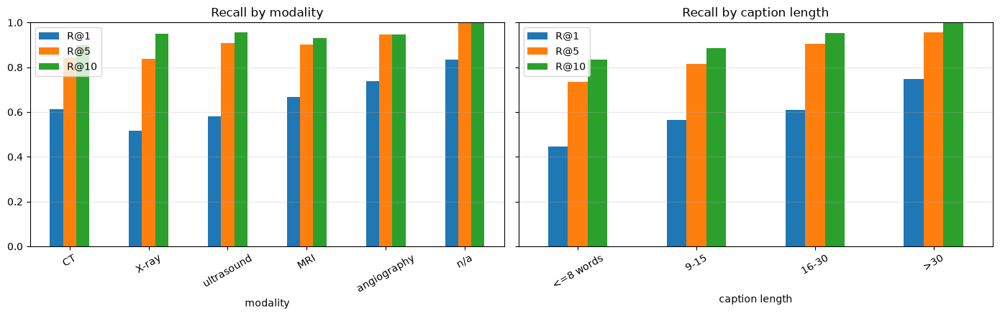

In [13]:
# (a) Recall by modality of the query's image and by caption length
def recall_table(group_col):
    g = per_query.groupby(group_col, observed=True)["rank"]
    out = pd.DataFrame({"n": g.size()})
    for k in KS:
        out[f"R@{k}"] = g.apply(lambda r, k=k: np.mean(r <= k))
    out["median rank"] = g.median()
    return out


by_mod = recall_table("modality").sort_values("n", ascending=False)
per_query["caption length"] = pd.cut(per_query["n_words"], [0, 8, 15, 30, np.inf],
                                     labels=["<=8 words", "9-15", "16-30", ">30"])
by_len = recall_table("caption length")

print("By modality of the target image:")
display(by_mod.round(3))
print("\nBy caption length:")
display(by_len.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, tbl, title in [(axes[0], by_mod, "Recall by modality"), (axes[1], by_len, "Recall by caption length")]:
    tbl[[f"R@{k}" for k in KS]].plot.bar(ax=ax, rot=30)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

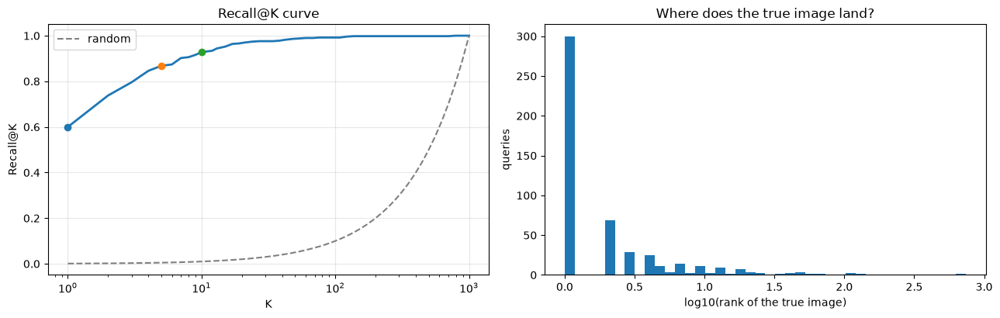

In [14]:
# (b) Recall@K curve and rank distribution
ks_curve = np.unique(np.round(np.logspace(0, np.log10(min(1000, N)), 60)).astype(int))
curve = [(ranks <= k).mean() for k in ks_curve]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(ks_curve, curve, lw=2)
axes[0].plot(ks_curve, ks_curve / N, "--", color="gray", label="random")
for k in KS:
    axes[0].scatter([k], [(ranks <= k).mean()], zorder=3)
axes[0].set_xscale("log")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Recall@K")
axes[0].set_title("Recall@K curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(np.log10(ranks), bins=40)
axes[1].set_xlabel("log10(rank of the true image)")
axes[1].set_ylabel("queries")
axes[1].set_title("Where does the true image land?")
plt.tight_layout()
plt.show()

In [15]:
# (c) What do the misses look like?
miss1 = per_query[per_query["rank"] > 1]
print(f"{len(miss1)} of {len(per_query)} queries miss at rank 1. Among those misses:")
print(f"  top-1 has an identical caption (not a real miss)      : {miss1['top1_same_caption'].mean():.1%}")
same_mod = (miss1["top1_modality"] == miss1["modality"]) & (miss1["modality"] != "n/a")
print(f"  top-1 has the same modality as the true image          : {same_mod.mean():.1%}")
print("\nMost frequent wrong top-1 modality pairs (true -> retrieved):")
pairs = (miss1[miss1["modality"] != "n/a"].groupby(["modality", "top1_modality"]).size()
         .sort_values(ascending=False).head(8))
print(pairs.to_string())

200 of 500 queries miss at rank 1. Among those misses:
  top-1 has an identical caption (not a real miss)      : 0.0%
  top-1 has the same modality as the true image          : 95.0%

Most frequent wrong top-1 modality pairs (true -> retrieved):
modality     top1_modality
CT           CT               74
X-ray        X-ray            52
ultrasound   ultrasound       36
MRI          MRI              24
angiography  angiography       4
CT           ultrasound        2
X-ray        angiography       2
CT           X-ray             1


36 queries with the true image outside the top-10


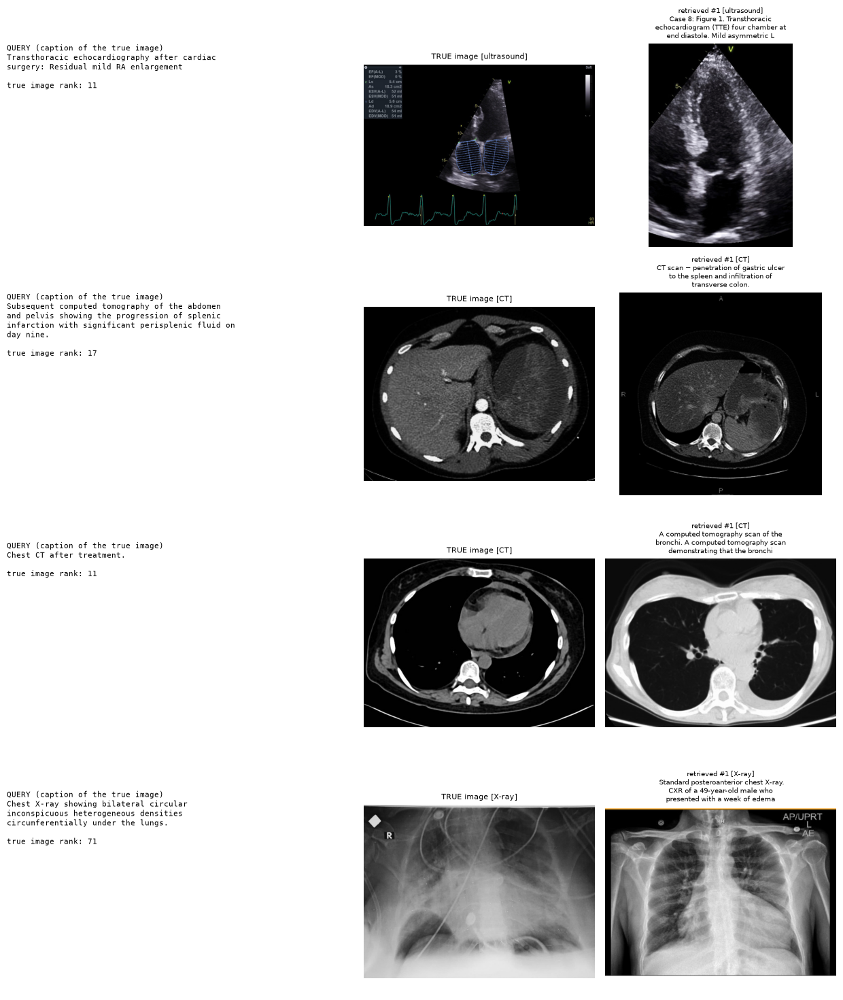

In [16]:
# (d) Look at failures (true image outside the top-10) next to what was retrieved instead
fail = np.where(ranks > 10)[0]
print(f"{len(fail)} queries with the true image outside the top-10")
pick = np.random.default_rng(SEED + 1).choice(fail, size=min(4, len(fail)), replace=False) if len(fail) else []

if len(pick):
    fig, axes = plt.subplots(len(pick), 3, figsize=(12.5, 3.7 * len(pick)), gridspec_kw={"width_ratios": [1.5, 1, 1]})
    axes = np.atleast_2d(axes)
    for row, qi in zip(axes, pick):
        t, p = eval_idx[qi], top[qi, 0]
        row[0].text(0, 1, "QUERY (caption of the true image)\n" + textwrap.fill(query_captions[qi][:420], 48)
                    + f"\n\ntrue image rank: {ranks[qi]}", va="top", fontsize=8, family="monospace",
                    transform=row[0].transAxes)
        row[0].axis("off")
        row[1].imshow(load_pil(db["image_id"][t]), cmap="gray")
        row[1].set_title(f"TRUE image [{db['modality'][t]}]", fontsize=8)
        row[2].imshow(load_pil(db["image_id"][p]), cmap="gray")
        row[2].set_title(f"retrieved #1 [{db['modality'][p]}]\n" + textwrap.fill(db["caption"][p][:100], 38), fontsize=7)
        row[1].axis("off")
        row[2].axis("off")
    plt.tight_layout()
    plt.show()

### How to read these numbers (caveats)

* **Possible train/test overlap.** BiomedCLIP was pre-trained on PMC-15M image-caption pairs from PubMed Central, and
  ROCOv2 images come from the PMC open-access subset, so many of these exact pairs may have been seen during
  pre-training. Treat Recall@K as an optimistic sanity check, not a clean held-out benchmark.
* **Gallery size.** Recall depends on how many images are searched (here the whole validation split).
  Do not compare directly with numbers from smaller galleries; the random baseline in the table gives the scale.
* **Duplicate captions** make the "true" image ambiguous; the duplicate-aware and unique-caption rows show how much this matters.
* **Truncation.** Captions longer than 256 tokens are cut off by the tokenizer.
* **Modality precision@10** and the modality breakdown show whether failures are *near misses* (right modality, wrong
  image) or *real* errors (wrong modality).

Natural next steps: image-to-text retrieval (transpose the same similarity matrix), query rewriting
(short keyword queries vs. full captions), and fine-tuning or re-ranking on ROCOv2.

helpers ready; 7 caption tags, 9 region patterns
pool: 1207 images (989 from the retrieval gallery)
accuracy 0.917 | macro recall 0.931

Confusion matrix (rows = ground truth):


,pred CT,pred MRI,pred ultrasound,pred angiography,pred PET,pred X-ray
true CT,365,3,1,44,0,4
true MRI,2,181,1,2,1,0
true ultrasound,0,0,200,12,0,0
true angiography,0,0,0,74,0,0
true PET,0,0,0,0,34,4
true X-ray,5,0,2,19,0,253



Per class:


,n,recall,precision,n predicted
modality,,,,
CT,417,0.875,0.981,372
MRI,187,0.968,0.984,184
ultrasound,212,0.943,0.980,204
angiography,74,1.000,0.490,151
PET,38,0.895,0.971,35
X-ray,279,0.907,0.969,261



Consistency check: 238 images are in both runs, predictions identical for 100.0%
A missed angiography: 0 | B false angiography: 77 | C correct angiography: 74 | D control: 239

What were the missed angiography images called instead?  {}
What were the false-angiography images really?           {'CT': 44, 'X-ray': 19, 'ultrasound': 12, 'MRI': 2}

=== A. TRUE angiography, predicted as something else (most confident first)  (showing 0) ===
   (no images in this group)

=== B. NOT angiography, predicted as angiography (most confident first)  (showing 8) ===


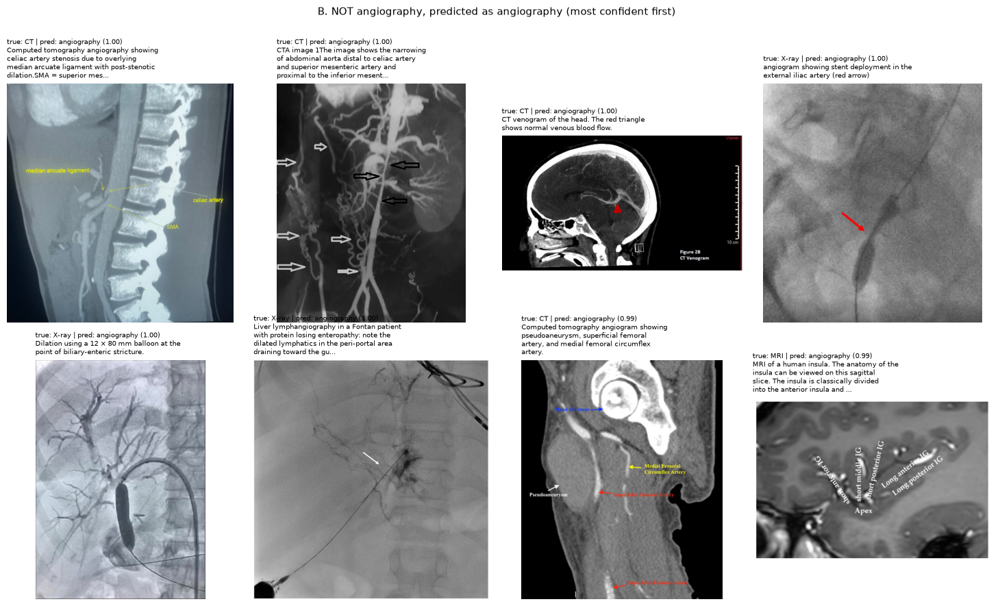


=== C. angiography classified correctly (most confident first)  (showing 8) ===


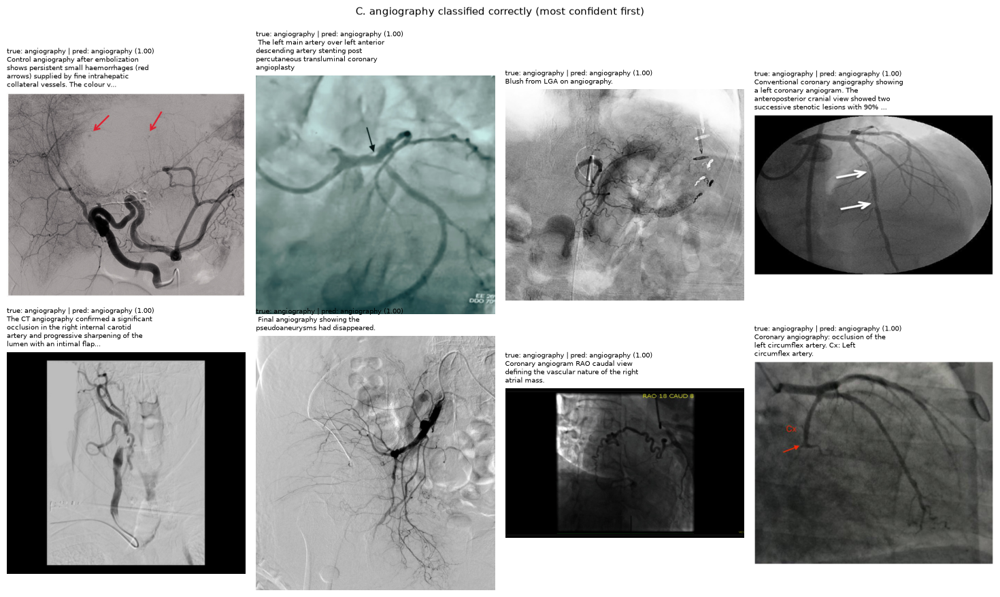


=== D. correct non-angiography whose caption mentions vessels / contrast (random)  (showing 8) ===


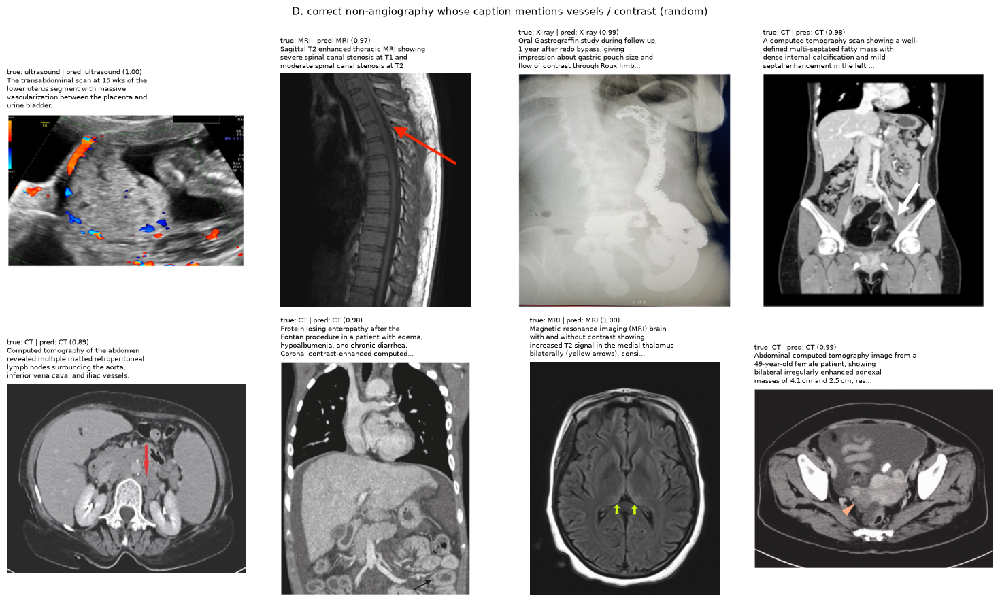

Share of captions (%) containing each tag, by group:


,n,colour_doppler,cta_mra,dsa_cath,contrast,vessel_words,annotated,multi_panel
group,,,,,,,,
A missed angio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B false angio,77.0,0.0,12.0,6.0,14.0,40.0,36.0,29.0
C correct angio,74.0,0.0,1.0,20.0,20.0,82.0,30.0,45.0
D correct non-angio (vessel/contrast words),239.0,3.0,3.0,1.0,56.0,51.0,49.0,25.0



Error rate with / without each tag:


,tag,pool,tag present,n,errors,rate,ci_low,ci_high,metric
0,colour_doppler,true angiography,True,0,0,NaN,NaN,NaN,missed (error rate)
1,colour_doppler,true angiography,False,74,0,0.000,0.000,0.049,missed (error rate)
2,colour_doppler,predicted angiography,True,0,0,NaN,NaN,NaN,false (1 - precision)
3,colour_doppler,predicted angiography,False,151,77,0.510,0.431,0.588,false (1 - precision)
4,cta_mra,true angiography,True,1,0,0.000,0.000,0.793,missed (error rate)
5,cta_mra,true angiography,False,73,0,0.000,0.000,0.050,missed (error rate)
6,cta_mra,predicted angiography,True,10,9,0.900,0.596,0.982,false (1 - precision)
7,cta_mra,predicted angiography,False,141,68,0.482,0.401,0.564,false (1 - precision)
8,dsa_cath,true angiography,True,15,0,0.000,0.000,0.204,missed (error rate)
9,dsa_cath,true angiography,False,59,0,0.000,0.000,0.061,missed (error rate)


pixel stats:   0%|          | 0/311 [00:00<?, ?it/s]


Median pixel statistics by group:


,colour_frac,mean_grey,dark_frac,bright_frac,contrast_sd,aspect,megapixels,n
group,,,,,,,,
B false angio,0.001,83.732,0.311,0.026,62.055,1.138,0.444,77
C correct angio,0.000,122.772,0.001,0.003,33.754,1.004,0.486,74
D correct non-angio (vessel/contrast words),0.002,60.118,0.340,0.010,54.957,1.200,0.418,80
E other correct (random),0.000,76.574,0.204,0.019,61.061,1.157,0.422,80


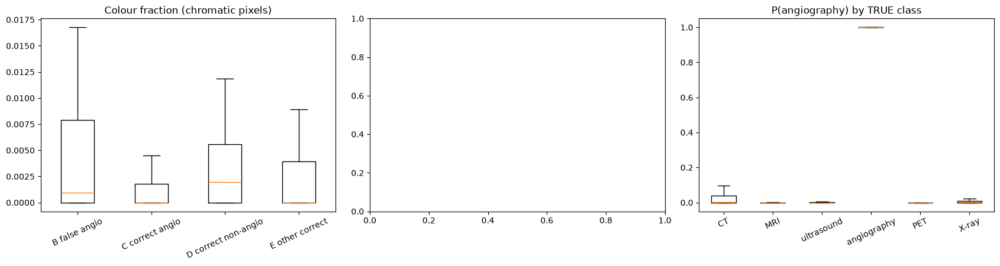


(too few missed or correct angiography images for a pixel-statistics AUC)
Mean concept probability by group (rows sum to 1 across concepts):


,colour Doppler ultrasound image,grayscale ultrasound image,CT angiography image,digital subtraction angiography image of blood vessels,contrast-enhanced CT scan,contrast-enhanced MRI scan,PET/CT fusion image,mammogram,plain X-ray radiograph,photograph or diagram with annotations,microscopy image,chart or schematic
group,,,,,,,,,,,,
B false angio,0.130000,0.010000,0.440000,0.130000,0.180000,0.010000,0.000000,0.040000,0.030000,0.000000,0.010000,0.020000
C correct angio,0.000000,0.000000,0.280000,0.680000,0.020000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
D correct non-angio (vessel/contrast words),0.130000,0.100000,0.120000,0.000000,0.320000,0.210000,0.030000,0.000000,0.090000,0.000000,0.010000,0.000000
other,0.090000,0.110000,0.090000,0.010000,0.210000,0.150000,0.060000,0.010000,0.260000,0.000000,0.010000,0.000000



Most likely fine-grained concept, by group (counts):


col_0,CT angiography image,PET/CT fusion image,chart or schematic,colour Doppler ultrasound image,contrast-enhanced CT scan,contrast-enhanced MRI scan,digital subtraction angiography image of blood vessels,grayscale ultrasound image,mammogram,microscopy image,photograph or diagram with annotations,plain X-ray radiograph
group,,,,,,,,,,,,
B false angio,35,0,1,11,12,0,11,1,3,1,0,2
C correct angio,24,0,0,0,1,0,49,0,0,0,0,0
D correct non-angio (vessel/contrast words),25,5,0,30,83,50,0,22,0,1,0,23


,prompt set,accuracy,angiography recall,angiography precision,n predicted angiography,n true angiography
0,default (as above),0.917,1.0,0.490,151,74
1,V1 descriptive,0.955,1.0,0.673,110,74
2,V2 definition-like,0.858,1.0,0.433,171,74


{'success (rank 1)': 300, 'near miss (rank 2-5, same modality)': 127, 'miss, same modality (rank > 10)': 35, 'miss, wrong modality (rank > 10)': 1, 'top-1 has an identical caption (dup.)': 0}


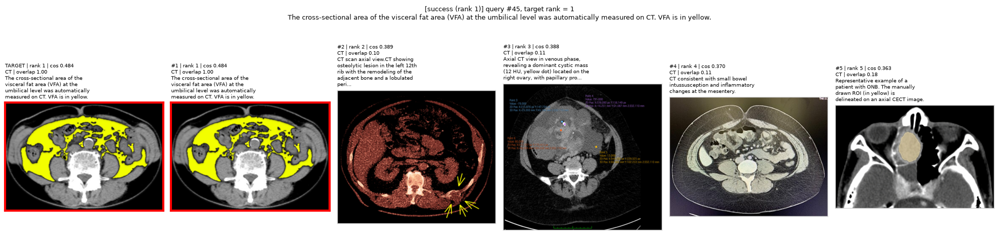

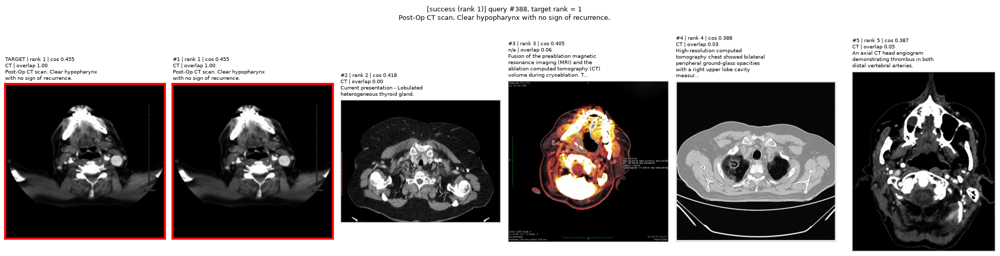

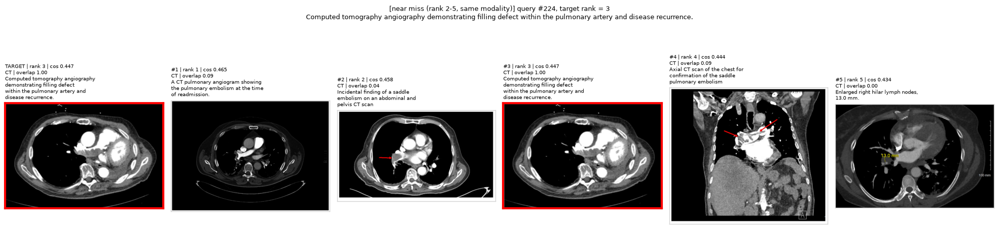

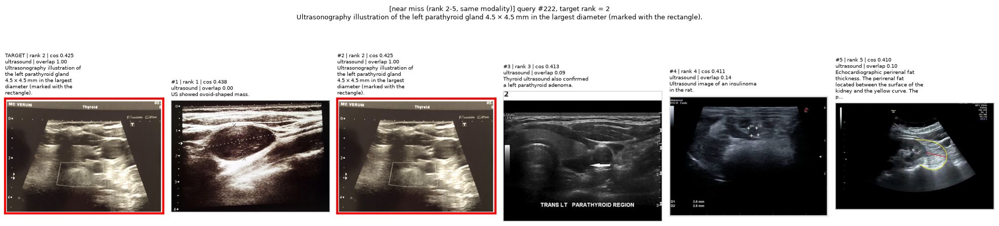

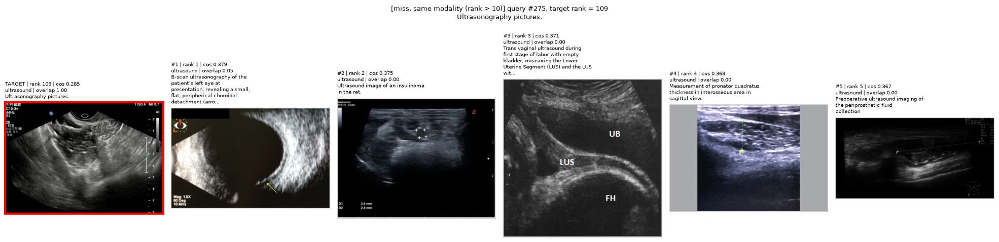

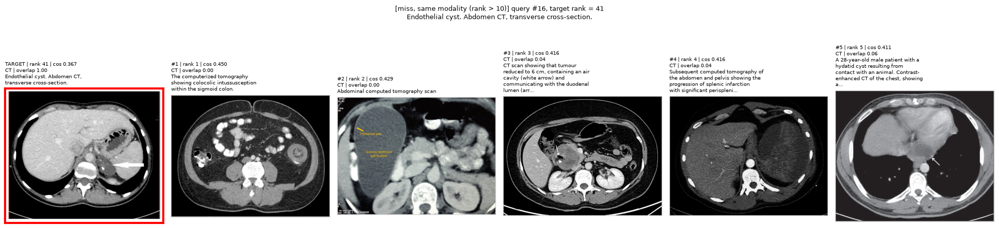

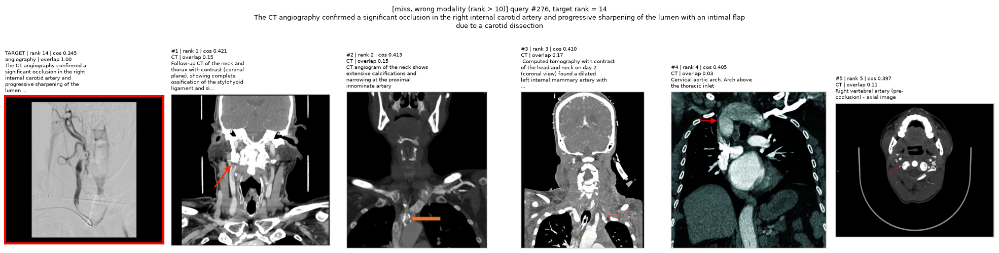

,category,query,target_id,target_rank,target_modality,top1_modality,cos_top1,cos_target,gap,overlap_top1,overlap_target
0,success (rank 1),45,ROCOv2_2023_valid_000768,1,CT,CT,0.484,0.484,0.000,1.000,1.0
1,success (rank 1),388,ROCOv2_2023_valid_007525,1,CT,CT,0.455,0.455,0.000,1.000,1.0
2,"near miss (rank 2-5, same modality)",224,ROCOv2_2023_valid_004218,3,CT,CT,0.465,0.447,0.017,0.091,1.0
3,"near miss (rank 2-5, same modality)",222,ROCOv2_2023_valid_004167,2,ultrasound,ultrasound,0.438,0.425,0.013,0.000,1.0
4,"miss, same modality (rank > 10)",275,ROCOv2_2023_valid_005116,109,ultrasound,ultrasound,0.379,0.285,0.094,0.050,1.0
5,"miss, same modality (rank > 10)",16,ROCOv2_2023_valid_000304,41,CT,CT,0.450,0.367,0.083,0.000,1.0
6,"miss, wrong modality (rank > 10)",276,ROCOv2_2023_valid_005124,14,angiography,CT,0.421,0.345,0.076,0.150,1.0


Outcome taxonomy over all queries:


,n,share %,median rank,median score gap
kind,,,,
success,300,60.0,1.0,0.000
"same modality, different region",102,20.4,4.0,0.027
same modality + region,88,17.6,3.0,0.023
different modality (or unlabelled),10,2.0,3.0,0.026



Spearman(density, log rank) = 0.32   (positive = images in crowded regions are ranked worse)
hubness: 6 images are the top-1 of 3+ different queries (max 4); top-1 concentration: 5.8% of queries land on just 10 images


,times top-1,modality,caption
ROCOv2_2023_valid_000649,4,X-ray,Chest X-ray anteroposterior view demonstrated ...
ROCOv2_2023_valid_001074,4,X-ray,Chest x-ray no findings suggestive of COVID-19...
ROCOv2_2023_valid_007808,4,ultrasound,"Parasternal long-axis view, with no vegetation..."
ROCOv2_2023_valid_008076,3,X-ray,Panoramic radiography at the first consultatio...
ROCOv2_2023_valid_001261,3,CT,Coronal CT image demonstrating the inflamed ap...
ROCOv2_2023_valid_008994,3,angiography,Coronary angiography showing evidence of criti...


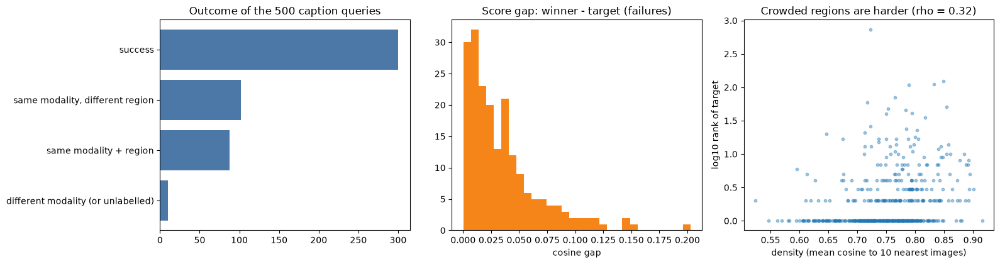


--- by modality


,modality,n,R@1,R@1 95% CI,R@5,R@5 95% CI,median rank
0,CT,199,0.613,"[0.54, 0.68]",0.844,"[0.79, 0.89]",1.0
1,X-ray,116,0.517,"[0.43, 0.61]",0.836,"[0.76, 0.89]",1.0
2,ultrasound,88,0.580,"[0.48, 0.68]",0.909,"[0.83, 0.95]",1.0
3,MRI,72,0.667,"[0.55, 0.76]",0.903,"[0.81, 0.95]",1.0
4,angiography,19,0.737,"[0.51, 0.88]",0.947,"[0.75, 0.99]",1.0
5,n/a,6,0.833,"[0.44, 0.97]",1.000,"[0.61, 1.00]",1.0



--- by region


,region,n,R@1,R@1 95% CI,R@5,R@5 95% CI,median rank
0,unspecified,139,0.583,"[0.50, 0.66]",0.842,"[0.77, 0.89]",1.0
1,chest/lung,108,0.500,"[0.41, 0.59]",0.796,"[0.71, 0.86]",1.5
2,abdomen,83,0.627,"[0.52, 0.72]",0.904,"[0.82, 0.95]",1.0
3,head/brain,58,0.759,"[0.63, 0.85]",0.966,"[0.88, 0.99]",1.0
4,neck/face,35,0.657,"[0.49, 0.79]",0.857,"[0.71, 0.94]",1.0
5,heart,21,0.571,"[0.37, 0.76]",0.857,"[0.65, 0.95]",1.0
6,pelvis,20,0.650,"[0.43, 0.82]",0.900,"[0.70, 0.97]",1.0
7,spine,18,0.444,"[0.25, 0.66]",0.889,"[0.67, 0.97]",2.0
8,limb/joint,15,0.733,"[0.48, 0.89]",1.000,"[0.80, 1.00]",1.0
9,breast,3,0.667,"[0.21, 0.94]",1.000,"[0.44, 1.00]",1.0



--- by caption length


,caption length,n,R@1,R@1 95% CI,R@5,R@5 95% CI,median rank
0,16-30,213,0.610,"[0.54, 0.67]",0.906,"[0.86, 0.94]",1.0
1,9-15,124,0.565,"[0.48, 0.65]",0.815,"[0.74, 0.87]",1.0
2,>30,91,0.747,"[0.65, 0.83]",0.956,"[0.89, 0.98]",1.0
3,<=8,72,0.444,"[0.34, 0.56]",0.736,"[0.62, 0.82]",2.0


... (3 outputs left out)

,Doppler / contrast / annotation in caption,n,R@1,R@1 95% CI,R@5,R@5 95% CI,median rank
0,False,295,0.498,"[0.44, 0.56]",0.800,"[0.75, 0.84]",2.0
1,True,205,0.746,"[0.68, 0.80]",0.966,"[0.93, 0.98]",1.0



Tree for 'target in top-5' (86.8% hits): 5-fold CV AUC = 0.72  (0.5 = no signal)
|--- n_words <= 12.50
|   |--- density <= 0.73
|   |   |--- n_words <= 8.50
|   |   |   |--- weights: [0.00, 20.00] class: 1
|   |   |--- n_words >  8.50
|   |   |   |--- weights: [4.00, 16.00] class: 1
|   |--- density >  0.73
|   |   |--- mod_CT <= 0.50
|   |   |   |--- weights: [16.00, 49.00] class: 1
|   |   |--- mod_CT >  0.50
|   |   |   |--- weights: [17.00, 24.00] class: 1
|--- n_words >  12.50
|   |--- density <= 0.84
|   |   |--- tag_annotated <= 0.50
|   |   |   |--- weights: [16.00, 167.00] class: 1
|   |   |--- tag_annotated >  0.50
|   |   |   |--- weights: [3.00, 146.00] class: 1
|   |--- density >  0.84
|   |   |--- weights: [10.00, 12.00] class: 1



,importance
density,0.502
n_words,0.379
mod_CT,0.079
tag_annotated,0.041



Tree for 'classification is WRONG' (8.3% errors): 5-fold CV AUC = 0.61
|--- cta_mra <= 0.50
|   |--- vessel_words <= 0.50
|   |   |--- dsa_cath <= 0.50
|   |   |   |--- weights: [907.00, 60.00] class: 0
|   |   |--- dsa_cath >  0.50
|   |   |   |--- weights: [13.00, 5.00] class: 0
|   |--- vessel_words >  0.50
|   |   |--- true_CT <= 0.50
|   |   |   |--- weights: [138.00, 7.00] class: 0
|   |   |--- true_CT >  0.50
|   |   |   |--- weights: [37.00, 19.00] class: 0
|--- cta_mra >  0.50
|   |--- n_words <= 17.50
|   |   |--- weights: [7.00, 4.00] class: 0
|   |--- n_words >  17.50
|   |   |--- weights: [5.00, 5.00] class: 0



In [ ]:
import math
import re
from sklearn.metrics import confusion_matrix, roc_auc_score

CLASSES = list(CUI_TO_MODALITY.values())
TEMPLATE = "this is a photo of "


def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion k/n (robust for small n)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


# keyword proxies for visual/clinical characteristics that captions mention
TAG_PATTERNS = {
    "colour_doppler": r"doppler|colou?r flow|power doppler|duplex",
    "cta_mra":        r"\bCTA\b|\bMRA\b|\bCT angio\w*|computed tomograph\w* angio\w*|\bMR angio\w*|magnetic resonance angio\w*",
    "dsa_cath":       r"\bDSA\b|digital subtraction|catheter|fluoroscop|\bcine\b",
    "contrast":       r"contrast|enhanc\w+|opacif\w+|injection|injected|gadolinium|iodinated",
    "vessel_words":   r"arter\w+|vein\w*|venous|vascular|vessel\w*|aneurysm\w*|stenos\w+|occlu\w+|aort\w+|carotid|coronary|thromb\w+",
    "annotated":      r"arrow\w*|asterisk|circle[ds]?|dotted|dashed|outlined|marked|label\w*|\barrowhead",
    "multi_panel":    r"\([a-h]\)|\b[a-h]\)|panel|left|right image|upper|lower",
}
TAG_RX = {k: re.compile(v, re.I) for k, v in TAG_PATTERNS.items()}

REGION_PATTERNS = {
    "head/brain":  r"\bbrain\b|cerebr\w+|intracranial|skull|head\b|cranial|\bsella\b|pituitary|cerebell\w+",
    "chest/lung":  r"\bchest\b|lung\w*|pulmonary|thora\w+|pleura\w*|mediastin\w+",
    "heart":       r"cardiac|heart|ventric\w+|atri\w+|coronary|myocard\w+|pericard\w+",
    "abdomen":     r"abdom\w+|liver|hepatic|renal|kidney|spleen|pancrea\w+|bowel|gastr\w+|colon",
    "pelvis":      r"pelvi\w+|uterus|uterine|prostat\w+|bladder|ovar\w+|fetus|fetal|obstetric",
    "spine":       r"spine|spinal|vertebra\w*|lumbar|cervical|thoracic spine|sacr\w+",
    "limb/joint":  r"knee|shoulder|\bhip\b|ankle|femur|femoral|tibia\w*|humer\w+|wrist|elbow|\bhand\b|\bfoot\b|limb|leg\b|arm\b",
    "neck/face":   r"neck|thyroid|carotid|jaw|mandib\w+|maxill\w+|dental|tooth|teeth|orbit\w*|sinus",
    "breast":      r"breast|mammo\w+",
}
REGION_RX = {k: re.compile(v, re.I) for k, v in REGION_PATTERNS.items()}


def tag_frame(captions_like):
    s = pd.Series(list(captions_like)).fillna("")
    return pd.DataFrame({k: s.str.contains(rx).to_numpy() for k, rx in TAG_RX.items()})


def first_region(caption):
    for name, rx in REGION_RX.items():
        if rx.search(caption):
            return name
    return "unspecified"


def jaccard(a, b):
    sa, sb = set(re.findall(r"[a-z0-9]+", a.lower())), set(re.findall(r"[a-z0-9]+", b.lower()))
    return len(sa & sb) / len(sa | sb) if (sa or sb) else 0.0


def show_images(df, title, n=8, ncols=4, wrap=42, caption_chars=150):
    """Grid of images with true label, prediction, confidence and caption."""
    df = df.head(n)
    print(f"\n=== {title}  (showing {len(df)}) ===")
    if df.empty:
        print("   (no images in this group)")
        return
    nrows = math.ceil(len(df) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.7 * ncols, 4.4 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), df.iterrows()):
        ax.imshow(load_pil(r["image_id"]))
        cap = r["caption"] if len(r["caption"]) <= caption_chars else r["caption"][:caption_chars] + "..."
        ax.set_title(f"true: {r['modality']} | pred: {r['pred']} ({r['confidence']:.2f})\n"
                     + textwrap.fill(cap, wrap), fontsize=7, loc="left")
    fig.suptitle(title, fontsize=11, y=1.0)
    plt.tight_layout()
    plt.show()


print("helpers ready;", len(TAG_PATTERNS), "caption tags,", len(REGION_PATTERNS), "region patterns")


mod_of = dict(zip(manual["image_id"], manual["modality"]))
pool_ids = [i for i in known if mod_of.get(i) in CLASSES and i in zip_index and i in cap_lookup]
pool_emb = np.stack([known[i] for i in pool_ids]).astype(np.float32)

class_txt = encode_texts([TEMPLATE + c for c in CLASSES])             # (6, 512) - the only new model calls
scale = float(model.logit_scale.exp().item())
logits = scale * pool_emb @ class_txt.T
logits -= logits.max(axis=1, keepdims=True)
probs = np.exp(logits)
probs /= probs.sum(axis=1, keepdims=True)

cls = pd.DataFrame({"image_id": pool_ids,
                    "caption": [cap_lookup[i] for i in pool_ids],
                    "modality": [mod_of[i] for i in pool_ids]})
cls["pred"] = [CLASSES[j] for j in probs.argmax(1)]
cls["confidence"] = probs.max(1)
cls["correct"] = cls["pred"] == cls["modality"]
for j, c in enumerate(CLASSES):
    cls[f"p_{c}"] = probs[:, j]
cls["in_gallery"] = cls["image_id"].isin(set(db["image_id"]))
cls["region"] = cls["caption"].map(first_region)
cls = pd.concat([cls, tag_frame(cls["caption"])], axis=1)
cls["n_words"] = cls["caption"].str.split().str.len()

print(f"pool: {len(cls)} images ({cls['in_gallery'].sum()} from the retrieval gallery)")
print(f"accuracy {cls['correct'].mean():.3f} | macro recall {cls.groupby('modality')['correct'].mean().mean():.3f}\n")

cm = pd.DataFrame(confusion_matrix(cls["modality"], cls["pred"], labels=CLASSES),
                  index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES])
print("Confusion matrix (rows = ground truth):")
display(cm)

per_cls = cls.groupby("modality")["correct"].agg(["size", "mean"]).reindex(CLASSES)
per_cls.columns = ["n", "recall"]
per_cls["precision"] = [(cls.loc[cls["pred"] == c, "correct"].mean() if (cls["pred"] == c).any() else np.nan) for c in CLASSES]
per_cls["n predicted"] = [(cls["pred"] == c).sum() for c in CLASSES]
print("\nPer class:")
display(per_cls.round(3))

# consistency with Experiment 1
p1 = OUT_DIR / "exp1_predictions.csv"
if p1.exists():
    e1 = pd.read_csv(p1, dtype={"image_id": str})
    e1["image_id"] = e1["image_id"].str.replace(r"\.(jpe?g|png)$", "", regex=True, case=False)
    m = e1.merge(cls[["image_id", "pred"]], on="image_id", suffixes=("_exp1", "_now"))
    if len(m):
        agree = (m["pred_exp1"] == m["pred_now"]).mean()
        print(f"\nConsistency check: {len(m)} images are in both runs, predictions identical for {agree:.1%}")
        if agree < 0.98:
            print("   -> below ~98%: check that SPLIT, MODEL_ID and the prompt template match Experiment 1.")
    else:
        print("\nNo image of exp1_predictions.csv is in this pool (different samples); skipping the consistency check.")
else:
    print("\n(outputs/exp1_predictions.csv not found; skipping the consistency check)")


ANG = "angiography"
grpA = cls[(cls["modality"] == ANG) & (cls["pred"] != ANG)].sort_values("confidence", ascending=False)
grpB = cls[(cls["modality"] != ANG) & (cls["pred"] == ANG)].sort_values("confidence", ascending=False)
grpC = cls[(cls["modality"] == ANG) & (cls["pred"] == ANG)].sort_values("confidence", ascending=False)
grpD = cls[(cls["modality"] != ANG) & (cls["pred"] == cls["modality"])
           & (cls["vessel_words"] | cls["contrast"])].sample(frac=1, random_state=SEED)
cls["group"] = "other"
for name, g in [("A missed angio", grpA), ("B false angio", grpB), ("C correct angio", grpC), ("D correct non-angio (vessel/contrast words)", grpD)]:
    cls.loc[g.index, "group"] = name

print(f"A missed angiography: {len(grpA)} | B false angiography: {len(grpB)} | "
      f"C correct angiography: {len(grpC)} | D control: {len(grpD)}")
print("\nWhat were the missed angiography images called instead? ", grpA["pred"].value_counts().to_dict())
print("What were the false-angiography images really?          ", grpB["modality"].value_counts().to_dict())

show_images(grpA, "A. TRUE angiography, predicted as something else (most confident first)")
show_images(grpB, "B. NOT angiography, predicted as angiography (most confident first)")
show_images(grpC.head(8), "C. angiography classified correctly (most confident first)")
show_images(grpD, "D. correct non-angiography whose caption mentions vessels / contrast (random)", n=8)


TAGS = list(TAG_PATTERNS)
G_ORDER = ["A missed angio", "B false angio", "C correct angio", "D correct non-angio (vessel/contrast words)"]

# (1) tag frequency per group
tag_tbl = cls[cls["group"].isin(G_ORDER)].groupby("group")[TAGS].mean().reindex(G_ORDER) * 100
tag_tbl.insert(0, "n", cls["group"].value_counts().reindex(G_ORDER))
print("Share of captions (%) containing each tag, by group:")
display(tag_tbl.round(0))

# error rates by tag (true angiography images: tag vs no tag), and precision of 'angiography' predictions
rows = []
ang_true = cls[cls["modality"] == ANG]
ang_pred = cls[cls["pred"] == ANG]
for t in TAGS:
    for side, df_, y, what in [("true angiography", ang_true, ~ang_true["correct"], "missed (error rate)"),
                               ("predicted angiography", ang_pred, ~ang_pred["correct"], "false (1 - precision)")]:
        for flag in (True, False):
            sel = df_[t] == flag
            k, n = int(y[sel].sum()), int(sel.sum())
            lo, hi = wilson(k, n)
            rows.append({"tag": t, "pool": side, "tag present": flag, "n": n, "errors": k,
                         "rate": k / n if n else np.nan, "ci_low": lo, "ci_high": hi, "metric": what})
tag_err = pd.DataFrame(rows)
print("\nError rate with / without each tag:")
display(tag_err.round(3))

# (2) pixel statistics on the A/B/C/D images + a random sample of other correct images
def pixel_stats(image_id, max_side=256):
    im = load_pil(image_id)
    w, h = im.size
    im.thumbnail((max_side, max_side))
    a = np.asarray(im).astype(np.float32)
    spread = a.max(axis=2) - a.min(axis=2)
    g = a.mean(axis=2)
    return {"colour_frac": float((spread > 30).mean()), "mean_grey": float(g.mean()),
            "dark_frac": float((g < 20).mean()), "bright_frac": float((g > 235).mean()),
            "contrast_sd": float(g.std()), "aspect": w / h, "megapixels": w * h / 1e6}


MAX_PER_GROUP = 80
sel = pd.concat([cls[cls["group"] == g].head(MAX_PER_GROUP) for g in G_ORDER]
                + [cls[(cls["group"] == "other") & cls["correct"]].sample(n=min(80, int(((cls["group"] == "other") & cls["correct"]).sum())), random_state=SEED)
                   .assign(group="E other correct (random)")])
px = pd.DataFrame([pixel_stats(i) for i in tqdm(sel["image_id"], desc="pixel stats")], index=sel.index)
px["group"] = sel["group"]
px["modality"] = sel["modality"]
print("\nMedian pixel statistics by group:")
display(px.groupby("group").median(numeric_only=True).assign(n=px["group"].value_counts()).round(3))

# plots
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
order = [g for g in G_ORDER + ["E other correct (random)"] if (px["group"] == g).any()]
short = {g: g.split(" (")[0] for g in order}
axes[0].boxplot([px.loc[px["group"] == g, "colour_frac"] for g in order], showfliers=False)
axes[0].set_xticks(range(1, len(order) + 1), labels=[short[g] for g in order])
axes[0].set_title("Colour fraction (chromatic pixels)")
axes[0].tick_params(axis="x", rotation=25)


axes[2].boxplot([cls.loc[cls["modality"] == c, "p_angiography"] for c in CLASSES], showfliers=False)
axes[2].set_xticks(range(1, len(CLASSES) + 1), labels=CLASSES)
axes[2].set_title("P(angiography) by TRUE class")
axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# how separable are missed vs. correct angiography by pixels alone?  (AUC; 0.5 = no signal)
from sklearn.metrics import roc_auc_score
ac = px[px["group"].isin(["A missed angio", "C correct angio"])]
if ac["group"].nunique() == 2 and ac["group"].value_counts().min() >= 5:
    print("\nAUC of each pixel statistic for 'missed' (A) vs 'correct' (C) angiography (0.5 = no signal, away from 0.5 = signal):")
    print({c: round(roc_auc_score(ac["group"] == "A missed angio", ac[c]), 2)
           for c in ["colour_frac", "mean_grey", "dark_frac", "bright_frac", "contrast_sd", "megapixels"]})
else:
    print("\n(too few missed or correct angiography images for a pixel-statistics AUC)")


CONCEPTS = [
    "a colour Doppler ultrasound image", "a grayscale ultrasound image", "a CT angiography image",
    "a digital subtraction angiography image of blood vessels", "a contrast-enhanced CT scan",
    "a contrast-enhanced MRI scan", "a PET/CT fusion image", "a mammogram", "a plain X-ray radiograph",
    "a photograph or diagram with annotations", "a microscopy image", "a chart or schematic",
]
concept_txt = encode_texts(CONCEPTS)                                   # prompts used as written
lg = scale * pool_emb @ concept_txt.T
lg -= lg.max(axis=1, keepdims=True)
cp = np.exp(lg)
cp /= cp.sum(axis=1, keepdims=True)
cp_df = pd.DataFrame(cp, index=cls.index, columns=[c.replace("a ", "", 1).replace("an ", "", 1) for c in CONCEPTS])
cp_df["group"] = cls["group"]
concept_by_group = cp_df.groupby("group").mean().reindex(G_ORDER + ["other"]).dropna(how="all")
print("Mean concept probability by group (rows sum to 1 across concepts):")
display(concept_by_group.round(2).style.background_gradient(axis=None, cmap="Blues"))

top_concept = cp_df.drop(columns="group").idxmax(axis=1)
print("\nMost likely fine-grained concept, by group (counts):")
display(pd.crosstab(cls["group"], top_concept).reindex([g for g in G_ORDER if g in set(cls["group"])]))

# held-out prompt variants
PROMPT_VARIANTS = {
    "default (as above)": (TEMPLATE, CLASSES),
    "V1 descriptive": (TEMPLATE, ["a CT scan", "an MRI scan", "an ultrasound image",
                                  "an angiogram showing contrast-filled blood vessels", "a PET scan", "an X-ray radiograph"]),
    "V2 definition-like": ("a medical image of ", ["computed tomography", "magnetic resonance imaging", "ultrasound (sonography)",
                                                   "vascular angiography with injected contrast", "positron emission tomography", "plain radiography"]),
}
rows = []
for name, (tmpl, labels) in PROMPT_VARIANTS.items():
    t = encode_texts([tmpl + l for l in labels])
    lgt = pool_emb @ t.T
    pr = np.array(CLASSES)[lgt.argmax(1)]
    is_ang = cls["modality"].to_numpy() == ANG
    pred_ang = pr == ANG
    rows.append({"prompt set": name, "accuracy": np.mean(pr == cls["modality"].to_numpy()),
                 "angiography recall": pred_ang[is_ang].mean() if is_ang.any() else np.nan,
                 "angiography precision": is_ang[pred_ang].mean() if pred_ang.any() else np.nan,
                 "n predicted angiography": int(pred_ang.sum()), "n true angiography": int(is_ang.sum())})
display(pd.DataFrame(rows).round(3))


CASES_PER_CATEGORY = 2
CASE_SEEDS = SEED
rs_case = np.random.default_rng(CASE_SEEDS)
pq = per_query.reset_index(drop=True).copy()
pq["top1_correct_modality"] = (pq["top1_modality"] == pq["modality"]) & (pq["modality"] != "n/a")
pq["top1_dup_caption"] = pq["top1_same_caption"]

cat_masks = {
    "success (rank 1)":                        pq["rank"] == 1,
    "near miss (rank 2-5, same modality)":     pq["rank"].between(2, 5) & pq["top1_correct_modality"],
    "miss, same modality (rank > 10)":         (pq["rank"] > 10) & pq["top1_correct_modality"],
    "miss, wrong modality (rank > 10)":        (pq["rank"] > 10) & ~pq["top1_correct_modality"] & (pq["modality"] != "n/a"),
    "top-1 has an identical caption (dup.)":   pq["top1_dup_caption"] & (pq["rank"] > 1),
}
CASES = []
for cat, mask in cat_masks.items():
    idx = np.where(mask.to_numpy())[0]
    pick = rs_case.choice(idx, size=min(CASES_PER_CATEGORY, len(idx)), replace=False) if len(idx) else []
    CASES += [(cat, int(j)) for j in pick]
print({cat: int(m.sum()) for cat, m in cat_masks.items()})


def show_case(cat, j, wrap=34, k=TOP_K_SHOW):
    gi = eval_idx[j]                                        # gallery row of the target
    s = cap_emb[j] @ image_emb.T
    order = np.argsort(-s)[:k]
    rank = int((s > s[gi]).sum() + 1)
    q = query_captions[j]
    cells_ = [("TARGET", gi)] + [(f"#{r + 1}", g) for r, g in enumerate(order)]
    fig, axes = plt.subplots(1, len(cells_), figsize=(3.3 * len(cells_), 5.0))
    for ax, (lab, g) in zip(axes, cells_):
        ax.imshow(load_pil(db["image_id"].iloc[g]))
        ax.set_xticks([]); ax.set_yticks([])
        is_t = g == gi
        for sp in ax.spines.values():
            sp.set_edgecolor("red" if is_t else "lightgray")
            sp.set_linewidth(3 if is_t else 1)
        cap = db["caption"].iloc[g]
        r_ = int((s > s[g]).sum() + 1)
        ax.set_title(f"{lab} | rank {r_} | cos {s[g]:.3f}\n{db['modality'].iloc[g]} | overlap {jaccard(q, cap):.2f}\n"
                     + textwrap.fill(cap[:130] + ("..." if len(cap) > 130 else ""), wrap), fontsize=7, loc="left")
    fig.suptitle(f"[{cat}] query #{j}, target rank = {rank}\n" + textwrap.fill(q, 150), fontsize=9, y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.show()
    return {"category": cat, "query": j, "target_id": db["image_id"].iloc[gi], "target_rank": rank,
            "target_modality": db["modality"].iloc[gi],
            "top1_modality": db["modality"].iloc[order[0]], "cos_top1": float(s[order[0]]), "cos_target": float(s[gi]),
            "gap": float(s[order[0]] - s[gi]), "overlap_top1": jaccard(q, db["caption"].iloc[order[0]]),
            "overlap_target": jaccard(q, db["caption"].iloc[gi])}


case_rows = [show_case(cat, j) for cat, j in CASES]
display(pd.DataFrame(case_rows).round(3))


cap_arr = db["caption"].to_numpy()
region_arr = np.array([first_region(c) for c in cap_arr])

rows = []
for j in range(len(pq)):
    gi, t1 = eval_idx[j], top[j, 0]
    q = query_captions[j]
    s_top1 = float(cap_emb[j] @ image_emb[t1])
    s_tgt = float(cap_emb[j] @ image_emb[gi])
    jac = jaccard(q, cap_arr[t1])
    same_mod = (mod_arr[t1] == mod_arr[gi]) and mod_arr[gi] != "n/a"
    same_reg = (region_arr[t1] == region_arr[gi]) and region_arr[gi] != "unspecified"
    if ranks[j] == 1:
        kind = "success"
    elif key_code[t1] == key_code[gi] or jac >= 0.8:
        kind = "duplicate / near-duplicate caption"
    elif same_mod and same_reg:
        kind = "same modality + region"
    elif same_mod:
        kind = "same modality, different region"
    else:
        kind = "different modality (or unlabelled)"
    rows.append({"query": j, "kind": kind, "rank": int(ranks[j]), "gap": s_top1 - s_tgt, "jaccard_top1": jac,
                 "cos_target": s_tgt, "region": region_arr[gi], "modality": mod_arr[gi]})
dx = pd.DataFrame(rows)

tax = dx["kind"].value_counts().rename("n").to_frame()
tax["share %"] = (tax["n"] / len(dx) * 100).round(1)
tax["median rank"] = dx.groupby("kind")["rank"].median()
tax["median score gap"] = dx.groupby("kind")["gap"].median().round(3)
print("Outcome taxonomy over all queries:")
display(tax)

# density and hubness
sims_gg = image_emb @ image_emb.T
np.fill_diagonal(sims_gg, -1)
KNN = 10
nn_density = np.sort(sims_gg, axis=1)[:, -KNN:].mean(axis=1)           # mean cosine to the 10 nearest images
del sims_gg
dx["density"] = nn_density[eval_idx]
dx["hit5"] = dx["rank"] <= 5
rho = pd.Series(dx["density"]).corr(pd.Series(np.log(dx["rank"])), method="spearman")
print(f"\nSpearman(density, log rank) = {rho:.2f}   (positive = images in crowded regions are ranked worse)")

hub_counts = pd.Series(top[:, 0]).value_counts()
hubs = hub_counts[hub_counts >= 3]
print(f"hubness: {len(hubs)} images are the top-1 of 3+ different queries (max {hub_counts.max()}); "
      f"top-1 concentration: {hub_counts.head(10).sum() / len(top):.1%} of queries land on just 10 images")
if len(hubs):
    hub_tbl = pd.DataFrame({"times top-1": hubs.values, "modality": mod_arr[hubs.index],
                            "caption": [cap_arr[i][:110] for i in hubs.index]}, index=db["image_id"].to_numpy()[hubs.index])
    display(hub_tbl.head(10))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
order = tax.index.tolist()
axes[0].barh(order, tax["n"], color="#4C78A8")
axes[0].invert_yaxis()
axes[0].set_title("Outcome of the 500 caption queries")
axes[1].hist(dx.loc[dx["rank"] > 1, "gap"], bins=30, color="#F58518")
axes[1].set_title("Score gap: winner - target (failures)")
axes[1].set_xlabel("cosine gap")
axes[2].scatter(dx["density"], np.log10(dx["rank"]), s=10, alpha=0.4)
axes[2].set_xlabel("density (mean cosine to 10 nearest images)")
axes[2].set_ylabel("log10 rank of target")
axes[2].set_title(f"Crowded regions are harder (rho = {rho:.2f})")
plt.tight_layout()
plt.show()


feat = pd.DataFrame({
    "n_words": per_query["n_words"].to_numpy(),
    "density": dx["density"].to_numpy(),
    "dup_caption": (~unique_cap).astype(int),
}).reset_index(drop=True)
qt = tag_frame(query_captions)
for c in qt.columns:
    feat[f"tag_{c}"] = qt[c].astype(int).to_numpy()
for m_ in sorted(set(mod_arr[eval_idx])):
    feat[f"mod_{m_}"] = (mod_arr[eval_idx] == m_).astype(int)
for r_ in sorted(set(dx["region"])):
    feat[f"region_{r_}"] = (dx["region"].to_numpy() == r_).astype(int)

# subgroup recall with Wilson intervals
def subgroup_table(by, name):
    rows = []
    for key, idx in dx.groupby(by).groups.items():
        r = dx.loc[idx, "rank"]
        n = len(r)
        k1, k5 = int((r <= 1).sum()), int((r <= 5).sum())
        l1, h1 = wilson(k1, n)
        l5, h5 = wilson(k5, n)
        rows.append({name: key, "n": n, "R@1": k1 / n, "R@1 95% CI": f"[{l1:.2f}, {h1:.2f}]",
                     "R@5": k5 / n, "R@5 95% CI": f"[{l5:.2f}, {h5:.2f}]", "median rank": r.median()})
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)


dx["caption length"] = pd.cut(per_query["n_words"].to_numpy(), [0, 8, 15, 30, np.inf], labels=["<=8", "9-15", "16-30", ">30"])
dx["density tertile"] = pd.qcut(dx["density"], 3, labels=["sparse", "medium", "crowded"])
dx["has Doppler/contrast/annotation words"] = (qt[["colour_doppler", "contrast", "annotated"]].any(axis=1)).to_numpy()
for by, name in [("modality", "modality"), ("region", "region"), ("caption length", "caption length"),
                 ("density tertile", "density"), ("has Doppler/contrast/annotation words", "Doppler / contrast / annotation in caption")]:
    print(f"\n--- by {name}")
    display(subgroup_table(by, name).round(3))

# decision tree: which simple features separate hits from misses?
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_predict

yhit = (dx["rank"].to_numpy() <= 5).astype(int)
if yhit.min() == yhit.max() or min(yhit.sum(), (1 - yhit).sum()) < 10:
    print("\nToo few hits or misses for a decision tree.")
else:
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEED)
    cvp = cross_val_predict(tree, feat, yhit, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    auc = roc_auc_score(yhit, cvp)
    tree.fit(feat, yhit)
    print(f"\nTree for 'target in top-5' ({yhit.mean():.1%} hits): 5-fold CV AUC = {auc:.2f}  (0.5 = no signal)")
    print(export_text(tree, feature_names=list(feat.columns), show_weights=True))
    imp = pd.Series(tree.feature_importances_, index=feat.columns).sort_values(ascending=False)
    display(imp[imp > 0].round(3).to_frame("importance"))

cls_feat = pd.concat([cls[["n_words"] + TAGS].astype(float).reset_index(drop=True),
                      pd.get_dummies(cls["modality"], prefix="true").astype(int).reset_index(drop=True),
                      pd.get_dummies(cls["region"], prefix="region").astype(int).reset_index(drop=True)], axis=1)
yerr = (~cls["correct"]).astype(int).to_numpy()
if min(yerr.sum(), (1 - yerr).sum()) >= 10:
    ctree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=SEED)
    cv_c = cross_val_predict(ctree, cls_feat, yerr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    ctree.fit(cls_feat, yerr)
    print(f"\nTree for 'classification is WRONG' ({yerr.mean():.1%} errors): 5-fold CV AUC = {roc_auc_score(yerr, cv_c):.2f}")
    print(export_text(ctree, feature_names=list(cls_feat.columns), show_weights=True))
